### 문제: PiPER의 초기 자세에서 EE 위치를 FK로 구하기

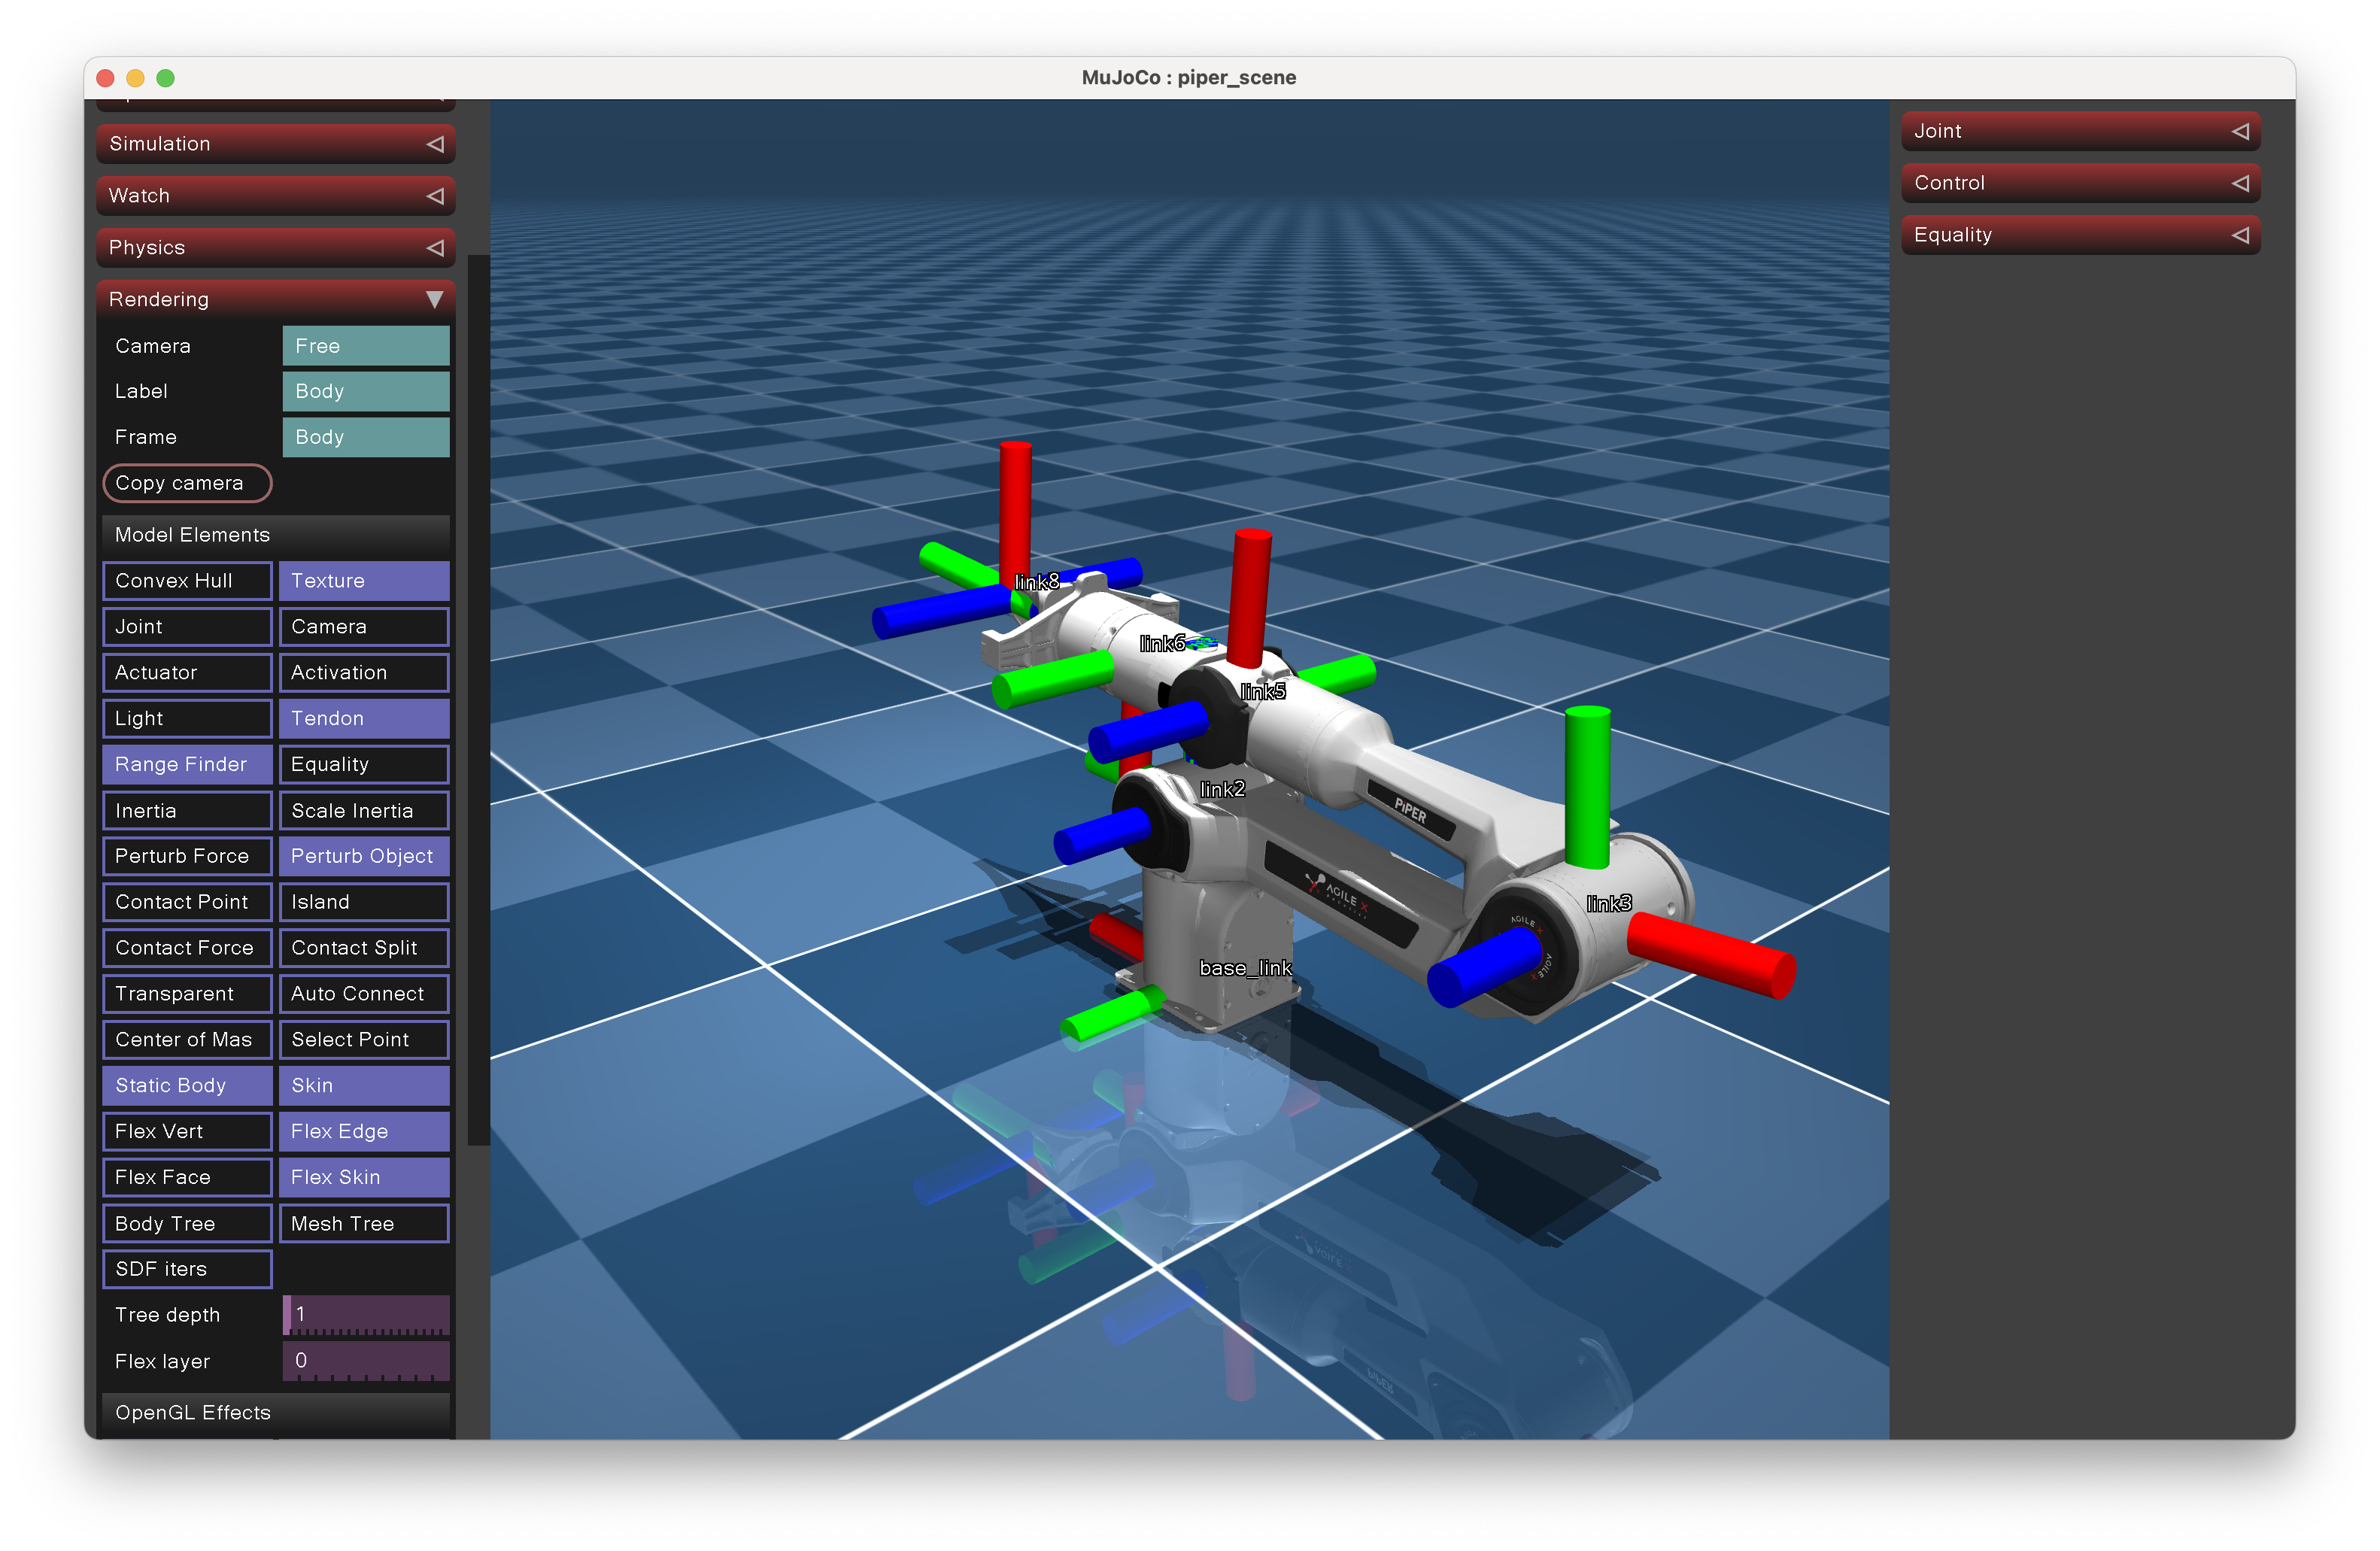



In [1]:
from pathlib import Path

import mujoco
import numpy as np

In [2]:
model = mujoco.MjModel.from_xml_path("../external/mujoco_menagerie/agilex_piper/scene.xml")

data = mujoco.MjData(model)  # Simulation state and data
mujoco.mj_resetData(model, data)  # Make initial pose
mujoco.mj_forward(model, data)  # Compute quantities for the current state

### 주어지는 정보 (예시)


① 부모 frame 기준 원점 **위치**


In [3]:
link = model.body("link1")

link.pos

array([0.   , 0.   , 0.123])

② 부모 frame 기준 고정 **자세**


In [4]:
link.quat  # quaternion

array([ 0.70710528,  0.        ,  0.        , -0.70710828])

In [5]:
rotation_flat = np.empty(9)
mujoco.mju_quat2Mat(rotation_flat, link.quat)  # rotation matrix
rotation = rotation_flat.reshape(3, 3)
rotation

array([[-4.24264237e-06,  1.00000000e+00,  0.00000000e+00],
       [-1.00000000e+00, -4.24264237e-06, -0.00000000e+00],
       [-0.00000000e+00,  0.00000000e+00,  1.00000000e+00]])

③ 부모 body의 Id


In [6]:
link.parentid

array([1], dtype=int32)

### Homogeneous Transformation Matrix 연산 (예시)

$$
T =
\begin{bmatrix}
R & t \\
0 & 1
\end{bmatrix}
$$



In [7]:
T_0_1 = np.eye(4)
T_0_1[:3, :3] = rotation
T_0_1[:3, 3] = link.pos

T_0_1

array([[-4.24264237e-06,  1.00000000e+00,  0.00000000e+00,
         0.00000000e+00],
       [-1.00000000e+00, -4.24264237e-06, -0.00000000e+00,
         0.00000000e+00],
       [-0.00000000e+00,  0.00000000e+00,  1.00000000e+00,
         1.23000000e-01],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00]])

---

## 함수



In [8]:
def get_local_transform(model, body_name):
    body = model.body(body_name)

    rotation_flat = np.empty(9)
    mujoco.mju_quat2Mat(rotation_flat, body.quat)

    T = np.eye(4)
    T[:3, :3] = rotation_flat.reshape(3, 3)
    T[:3, 3] = body.pos

    return T

In [9]:
def get_world_transform(data, body_name):
    body = data.body(body_name)

    T = np.eye(4)
    T[:3, :3] = body.xmat.reshape(3, 3)
    T[:3, 3] = body.xpos

    return T

In [10]:
T_0_1 = get_local_transform(model, "link1")
T_1_2 = get_local_transform(model, "link2")
T_2_3 = get_local_transform(model, "link3")
T_3_4 = get_local_transform(model, "link4")
T_4_5 = get_local_transform(model, "link5")
T_5_6 = get_local_transform(model, "link6")

---

### link 2 비교


In [11]:
T_0_1 @ T_1_2

array([[-1.00000000e+00,  2.49705035e-11,  8.24264237e-06,
         0.00000000e+00],
       [ 8.24264237e-06,  4.00000000e-06,  1.00000000e+00,
         0.00000000e+00],
       [-8.00004507e-12,  1.00000000e+00, -4.00000000e-06,
         1.23000000e-01],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00]])

In [12]:
T_world_link2 = get_world_transform(data, "link2")

np.set_printoptions(precision=6, suppress=True)
print(T_world_link2)

[[-1.        0.        0.000008  0.      ]
 [ 0.000008  0.000004  1.        0.      ]
 [-0.        1.       -0.000004  0.123   ]
 [ 0.        0.        0.        1.      ]]


---


In [13]:
T_0_1 @ T_1_2 @ T_2_3

array([[-0.994909,  0.100779,  0.000008, -0.28358 ],
       [ 0.000009,  0.000003,  1.      ,  0.000002],
       [ 0.100779,  0.994909, -0.000004,  0.151726],
       [ 0.      ,  0.      ,  0.      ,  1.      ]])

In [14]:
T_world_link3 = get_world_transform(data, "link3")

np.set_printoptions(precision=6, suppress=True)
print(T_world_link3)

[[-0.994909  0.100779  0.000008 -0.28358 ]
 [ 0.000009  0.000003  1.        0.000002]
 [ 0.100779  0.994909 -0.000004  0.151726]
 [ 0.        0.        0.        1.      ]]


---


In [15]:
T_0_1 @ T_1_2 @ T_2_3 @ T_3_4

array([[-0.087136, -0.000011,  0.996196, -0.035698],
       [ 0.000004, -1.      , -0.000011,  0.000001],
       [ 0.996196,  0.000003,  0.087136,  0.195482],
       [ 0.      ,  0.      ,  0.      ,  1.      ]])

In [16]:
T_world_link4 = get_world_transform(data, "link4")

np.set_printoptions(precision=6, suppress=True)
print(T_world_link4)

[[-0.087136 -0.000011  0.996196 -0.035698]
 [ 0.000004 -1.       -0.000011  0.000001]
 [ 0.996196  0.000003  0.087136  0.195482]
 [ 0.        0.        0.        1.      ]]


---


In [17]:
T_0_1 @ T_1_2 @ T_2_3 @ T_3_4 @ T_4_5

array([[-0.087136,  0.996196,  0.000007, -0.035698],
       [ 0.000004, -0.000007,  1.      ,  0.000001],
       [ 0.996196,  0.087136, -0.000003,  0.195482],
       [ 0.      ,  0.      ,  0.      ,  1.      ]])

In [18]:
T_world_link5 = get_world_transform(data, "link5")

np.set_printoptions(precision=6, suppress=True)
print(T_world_link5)

[[-0.087136  0.996196  0.000007 -0.035698]
 [ 0.000004 -0.000007  1.        0.000001]
 [ 0.996196  0.087136 -0.000003  0.195482]
 [ 0.        0.        0.        1.      ]]


---


In [19]:
T_0_1 @ T_1_2 @ T_2_3 @ T_3_4 @ T_4_5 @ T_5_6

array([[ 0.087136,  0.000003,  0.996196,  0.054956],
       [-0.000004,  1.      , -0.000002,  0.001416],
       [-0.996196, -0.000004,  0.087136,  0.203411],
       [ 0.      ,  0.      ,  0.      ,  1.      ]])

In [20]:
T_world_link6 = get_world_transform(data, "link6")

np.set_printoptions(precision=6, suppress=True)
print(T_world_link6)

[[ 0.087136  0.000003  0.996196  0.054956]
 [-0.000004  1.       -0.000002  0.001416]
 [-0.996196 -0.000004  0.087136  0.203411]
 [ 0.        0.        0.        1.      ]]
